In [36]:
%matplotlib auto
import cv2
import numpy as np
from IPython.display import display
from PIL import Image
import os

Using matplotlib backend: inline


In [2]:
image = cv2.imread("examplePic/4_Move_studetcap.jpg")
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

[ WARN:0@1.649] global loadsave.cpp:241 findDecoder imread_('examplePic/4_Move_studetcap.jpg'): can't open/read file: check file path/integrity


error: OpenCV(4.10.0) /io/opencv/modules/imgproc/src/color.cpp:196: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


In [5]:
# Apply edge detection
edges = cv2.Canny(gray, 50, 150)

print(type(edges))
# cv2.imshow("Lines Detected", edges)


<class 'numpy.ndarray'>


In [6]:
# Apply Hough Line Transformation
lines = cv2.HoughLines(edges, 1, np.pi / 360, 250)

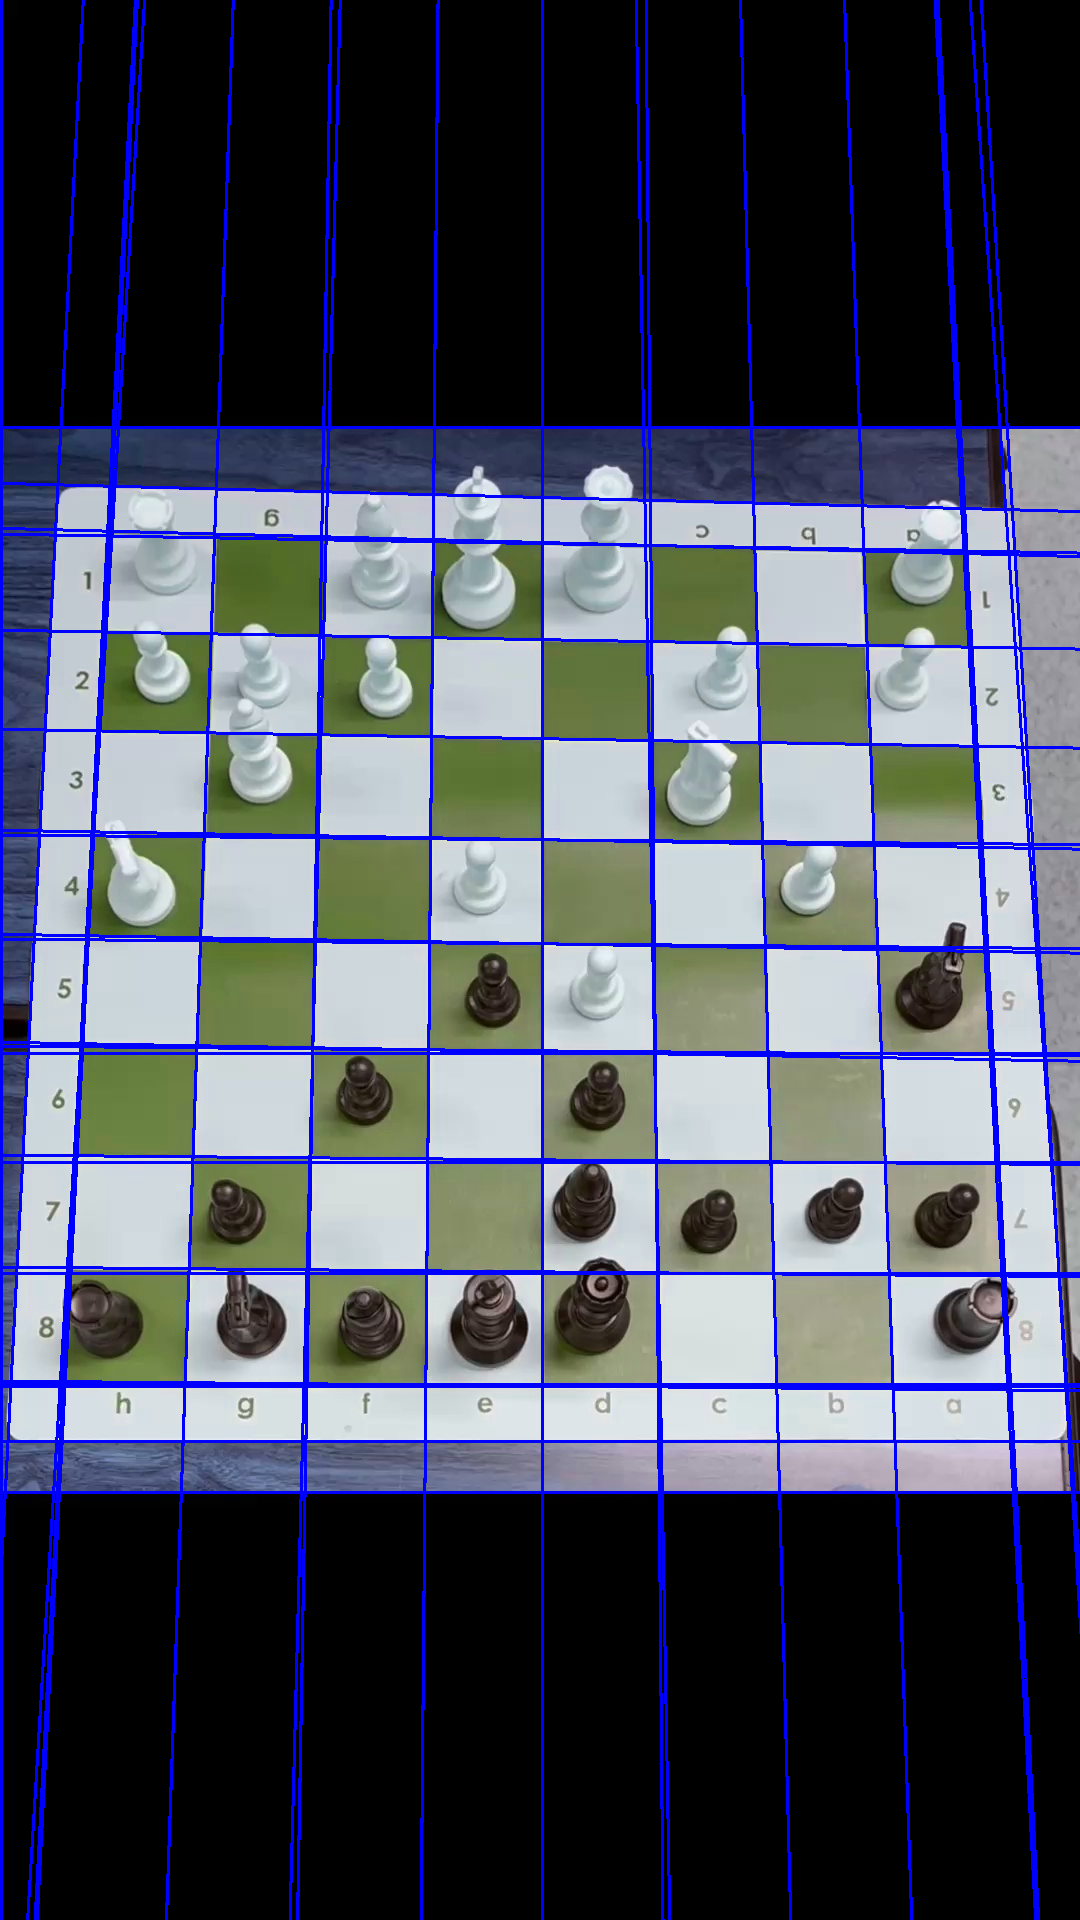

In [7]:
# Draw lines on the image
for line in lines:
    rho, theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 3000 * (-b))
    y1 = int(y0 + 3000 * (a))
    x2 = int(x0 - 3000 * (-b))
    y2 = int(y0 - 3000 * (a))
    cv2.line(image, (x1, y1), (x2, y2), (0, 0, 255), 2)

display(Image.fromarray(image))
#cv2.imshow("Lines Detected", image)


In [8]:
#
# 
# 
# 
# 
# ############ the grid detection
#
# 
# 
# 
# 
# 
# #

In [2]:
def shortest_des_point_line(rho, theta, p_x, p_y):
    
    # if result < 0 point is left
    # if result > 0 point is right
    # dif is xcos(ta) + ysin(ta) - rho

    return float((p_y * np.cos(theta) + p_x * np.sin(theta)) - rho)


In [3]:
def lineDistance_dif(rho1, rho2):
    return abs(rho1) - abs(rho2)   # (1) - (2) if > 0 (1) is right hand side of (2)      < 0 otherwiss

In [4]:
# is point is left or top
def isPointIsLeftOfTheline(startPoint, line):
    return shortest_des_point_line(line[0], line[1], startPoint[0], startPoint[1]) < 0

def findNearestLineWithIndexRet(startPoint, lines):
    lpds= [(
        line[0], #rho, 
        line[1], #theta, 
        abs(shortest_des_point_line(line[0], line[1], startPoint[0], startPoint[1])),
        idx)
        for idx, line in enumerate(lines)]
    sortedLpds = sorted(lpds, key = lambda x: x[2])
    return (sortedLpds[0][0:2], sortedLpds[0][3])


# start point (x, y)   lines = [(rho, theta)]
def findNearestLine(startPoint, lines):
    # line point distance (rho, theta, distance)
    line, idx = findNearestLineWithIndexRet(startPoint, lines)
    return line

In [6]:
# start point (x, y)    
# lines = [ (rho, theta)]    
# we assume line is either horizontal or vertical
# we assume line is either side  left-right or top-down
# amt amount of line to be recruite (centerline is not included)
# direction is either true is left false is right (reference form polar)

def filterLeftByRelDistance(lineWithDistance, isLeft: bool):
                # < 0 mean its rho is less than center
    return (lineWithDistance[2] <= 0) == isLeft


def select_lineByDistance(minBlockLength: float, maxBlockLength: float, startPoint, lines, amt, isLeft: bool):
    
    centerLine = findNearestLine(startPoint, lines)

    # line with distance
    #(rho, theta, difFrameMastsesr)
    lds = [(rho, theta, lineDistance_dif(rho, centerLine[0])) for rho, theta in lines]
    # filter to the wanted direction
    lds = list(filter(lambda x: filterLeftByRelDistance(x, isLeft),lds))
    # sorted by length
    lds = sorted(lds, key = lambda x: abs(x[2]))

    resultAmt = 0

    curline = (centerLine[0], centerLine[1], 0)
    result = []

    for line in lds:
        #print("------finding block")
        #print("------------dis of line ", line[2])
        #print("------------dis of curline", curline[2])
        lineDifSize = abs(line[2] - curline[2])
        if lineDifSize in range(minBlockLength, maxBlockLength):
            result.append(line)
            curline = line
            resultAmt = resultAmt + 1
            if (resultAmt == amt):
                break

    return [(rho, theta) for rho, theta, _ in result], centerLine




In [7]:
def filterVerHolByTheta(line, isVertical):
    theta = line[1]
    verAng0 = 45/180*np.pi
    verAng1 = 125/180*np.pi

    if (theta < 0 or theta >= np.pi):
        print(theta)
        print("invalid angle")

    return isVertical == ((theta >= verAng1)or (theta <= verAng0))


def select_lineByDirection(lines, isVertical):
    return list(filter(lambda x: filterVerHolByTheta(x, isVertical),lines))

In [8]:
def selectLine(lines, minBoxWidth, maxBoxWidth, startingPoint):

    #print("starting point is ")
    #print(startingPoint)

    # detectVertical

    linePerSide = 4

    allVerticalLine = select_lineByDirection(lines, True)
    #print("all vertical line is ")
    #print(allVerticalLine)
    leftVerticals , centerLine0 = select_lineByDistance(minBoxWidth, maxBoxWidth, startingPoint, allVerticalLine, linePerSide, True)
    rightVerticals, centerLine1 = select_lineByDistance(minBoxWidth, maxBoxWidth, startingPoint, allVerticalLine, linePerSide, False)
    VerticalResult = leftVerticals[::-1] + [centerLine1] + rightVerticals#leftVerticals[::-1] + [centerLine0]# + rightVerticals

    allHorizontalLine = select_lineByDirection(lines, False)
    #print("all vertical line is ")
    #print(allVerticalLine)
    leftHorizon , centerLineH0 = select_lineByDistance(minBoxWidth, maxBoxWidth, startingPoint, allHorizontalLine, linePerSide, True)
    rightHorizon, centerLineH1 = select_lineByDistance(minBoxWidth, maxBoxWidth, startingPoint, allHorizontalLine, linePerSide, False)
    HorizonResult = leftHorizon[::-1] + [centerLineH0] + rightHorizon#leftVerticals[::-1] + [centerLine0]# + rightVerticals


    return (VerticalResult, HorizonResult)

In [9]:
def embededLine(image, lines):
    for rho, theta in lines:
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 3000 * (-b))
        y1 = int(y0 + 3000 * (a))
        x2 = int(x0 - 3000 * (-b))
        y2 = int(y0 - 3000 * (a))
        cv2.line(image, (x1, y1), (x2, y2), (0, 0, 255), 2)

def embededPoint(image, point):
    
    color = (0,0,255)
    radius = 40
    thickness = -1
    cv2.circle(image, point[::-1], radius, color, thickness)

def embededParameter(image, name, value):     # embed also support  gray scale image
    
    text = f"{name}: {str(value)}"
    position = (60, 30)  # Adjust position for each line
    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = 3
    color = (0, 255, 0)  # Green text
    thickness = 2

    cv2.putText(image, text, position, font, font_scale, color, thickness)
    return image



In [10]:
def gridDetect(image, minBoxValueSize, maxBoxValueSize, startingPoint, poolAmtHough):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Apply edge detection
    edges = cv2.Canny(gray, 50, 150)
    lines = cv2.HoughLines(edges, 1, np.pi / 360, poolAmtHough)
    myLine = [tuple(line[0]) for line in lines ]
    VerticalResult, HorizontalResult = selectLine(myLine, minBoxValueSize, maxBoxValueSize, startingPoint)
    return VerticalResult, HorizontalResult

In [11]:
def nextConsecutiveCell(resultLine, resultLineIdx, point, maxLineIdx): # amount of line 

    if (resultLineIdx == 0):
        return 1
    if (resultLineIdx == maxLineIdx):
        return maxLineIdx - 1

    ### the point is in the left of the line 
    if isPointIsLeftOfTheline(point, resultLine):
        return resultLineIdx - 1
    else:
        return resultLineIdx + 1

def cellDetect(HorizontalResults, VerticalResults, point):


    lineH, idxH = findNearestLineWithIndexRet(point, HorizontalResults)
    lineV, idxV = findNearestLineWithIndexRet(point, VerticalResults)

    idxHc = nextConsecutiveCell(lineH, idxH, point, len(HorizontalResults)-1)
    idxVc = nextConsecutiveCell(lineV, idxV, point, len(VerticalResults)-1)

    #### return (x, y)
    return min(idxH, idxHc), min(idxV, idxVc)

In [12]:
maskGrid         = None
HSV_HUMAN_LOWER  = np.array([ 0,  48,  80], dtype = "uint8")
HSV_HUMAN_UPPER  = np.array([20, 255, 255], dtype = "uint8")

In [43]:
def s2_markGrid(rho, theta, xOrdi, yOrdi, isLeft):
    #print((yOrdi * np.cos(theta)).dtype)
    absDisToLineGrid = \
        abs(yOrdi * np.cos(theta) + xOrdi * np.sin(theta)) - abs(rho)
    
    return isLeft == (absDisToLineGrid < 0)

def s2_initGridMask(image, topLine, rightLine, downLine, leftLine):
    global maskGrid

    x, y = np.ogrid[:image.shape[0],:image.shape[1]]

    # top and down
    topClean   = s2_markGrid(topLine  [0], topLine  [1], x, y, False)
    downClean  = s2_markGrid(downLine [0], downLine [1], x, y, True )
    # right and left
    rightClean = s2_markGrid(rightLine[0], rightLine[1], x, y, True )
    leftClean  = s2_markGrid(leftLine [0], leftLine [1], x, y, False)

    maskGrid = topClean & downClean & rightClean & leftClean

def s2_initMaskHuman(image, boundMask):

    # skinMask = cv2.inRange(imageHSV, HSV_HUMAN_LOWER, HSV_HUMAN_UPPER).astype(bool)

    # print("skinMask", skinMask.shape, skinMask.dtype)
    # print("boundMask", boundMask.shape, boundMask.dtype)

    # summaryMask = skinMask & boundMask
    # display(Image.fromarray(summaryMask))

    # Kovac et al

    B_Frame = image[:, :,0]
    G_Frame = image[:, :,1]
    R_Frame = image[:, :,2]

    bgr_max = np.maximum.reduce([B_Frame, G_Frame, R_Frame])
    bgr_min = np.minimum.reduce([B_Frame, G_Frame, R_Frame])

    r1 = np.logical_and.reduce([R_Frame > 95, G_Frame > 40, B_Frame > 20,
                         (bgr_max - bgr_min) > 15, abs(R_Frame- G_Frame) > 15,
                         R_Frame > G_Frame, R_Frame > B_Frame])
    
    # r2 = np.logical_and.reduce([R_Frame > 220, G_Frame > 210, B_Frame > 170,
    #                             abs(R_Frame- G_Frame) <= 15, 
    #                             R_Frame > B_Frame, G_Frame > B_Frame])

    summaryMask = r1
    summaryMask = np.logical_and(summaryMask, boundMask)

    return summaryMask

    

In [49]:



def s2_handDetect(srcVideoPath, desVideoPath):
    print(srcVideoPath)

    cap  =  cv2.VideoCapture(srcVideoPath)

    #### init video
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    out = cv2.VideoWriter(desVideoPath, fourcc, fps, frame_size)

    VerticalResult = None
    HorizontalResult = None

    while cap.isOpened():
        #print("xxxx")
        ret, frame = cap.read()
        if not ret:
            break
        #print("finread")
        VerticalResult, HorizontalResult = \
            gridDetect(frame, 88, 178, (frame.shape[0]//2, frame.shape[1]//2), 250)
        
        s2_initGridMask(frame, HorizontalResult[0], VerticalResult[-1], HorizontalResult[-1], VerticalResult[0])

        maskedPic = s2_initMaskHuman(frame, maskGrid)
        #print("masking")
        frame[maskedPic] = [0,0,255]
        #print("fin")
        count = np.sum(maskedPic)

        cv2.putText(frame, f"handCorlor Count{str(count)}", 
                    (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 
                    1, (0, 255, 0), 2)
        out.write(frame)
        
    cap.release()
    out.release()
    print(f"Video capture and writing complete.{desVideoPath}")


video_directory = 'vdo'
output_directory = 'out_withHandMask'


#s2_handDetect(os.path.join(video_directory,"2_move_student.mp4"), os.path.join(output_directory, "2_move_student.mp4"))

for video_file in os.listdir(video_directory):
        
    s2_handDetect(os.path.join(video_directory,video_file), os.path.join(output_directory, f"outV_{video_file}"))


    

vdo/6_Move_student.mp4
Video capture and writing complete.out_withHandMask/outV_6_Move_student.mp4
vdo/8_Move_student.mp4
Video capture and writing complete.out_withHandMask/outV_8_Move_student.mp4
vdo/4_Move_studet.mp4
Video capture and writing complete.out_withHandMask/outV_4_Move_studet.mp4
vdo/2_Move_rotate_student.mp4
Video capture and writing complete.out_withHandMask/outV_2_Move_rotate_student.mp4
vdo/2_move_student.mp4
Video capture and writing complete.out_withHandMask/outV_2_move_student.mp4


(1920, 1080, 3)


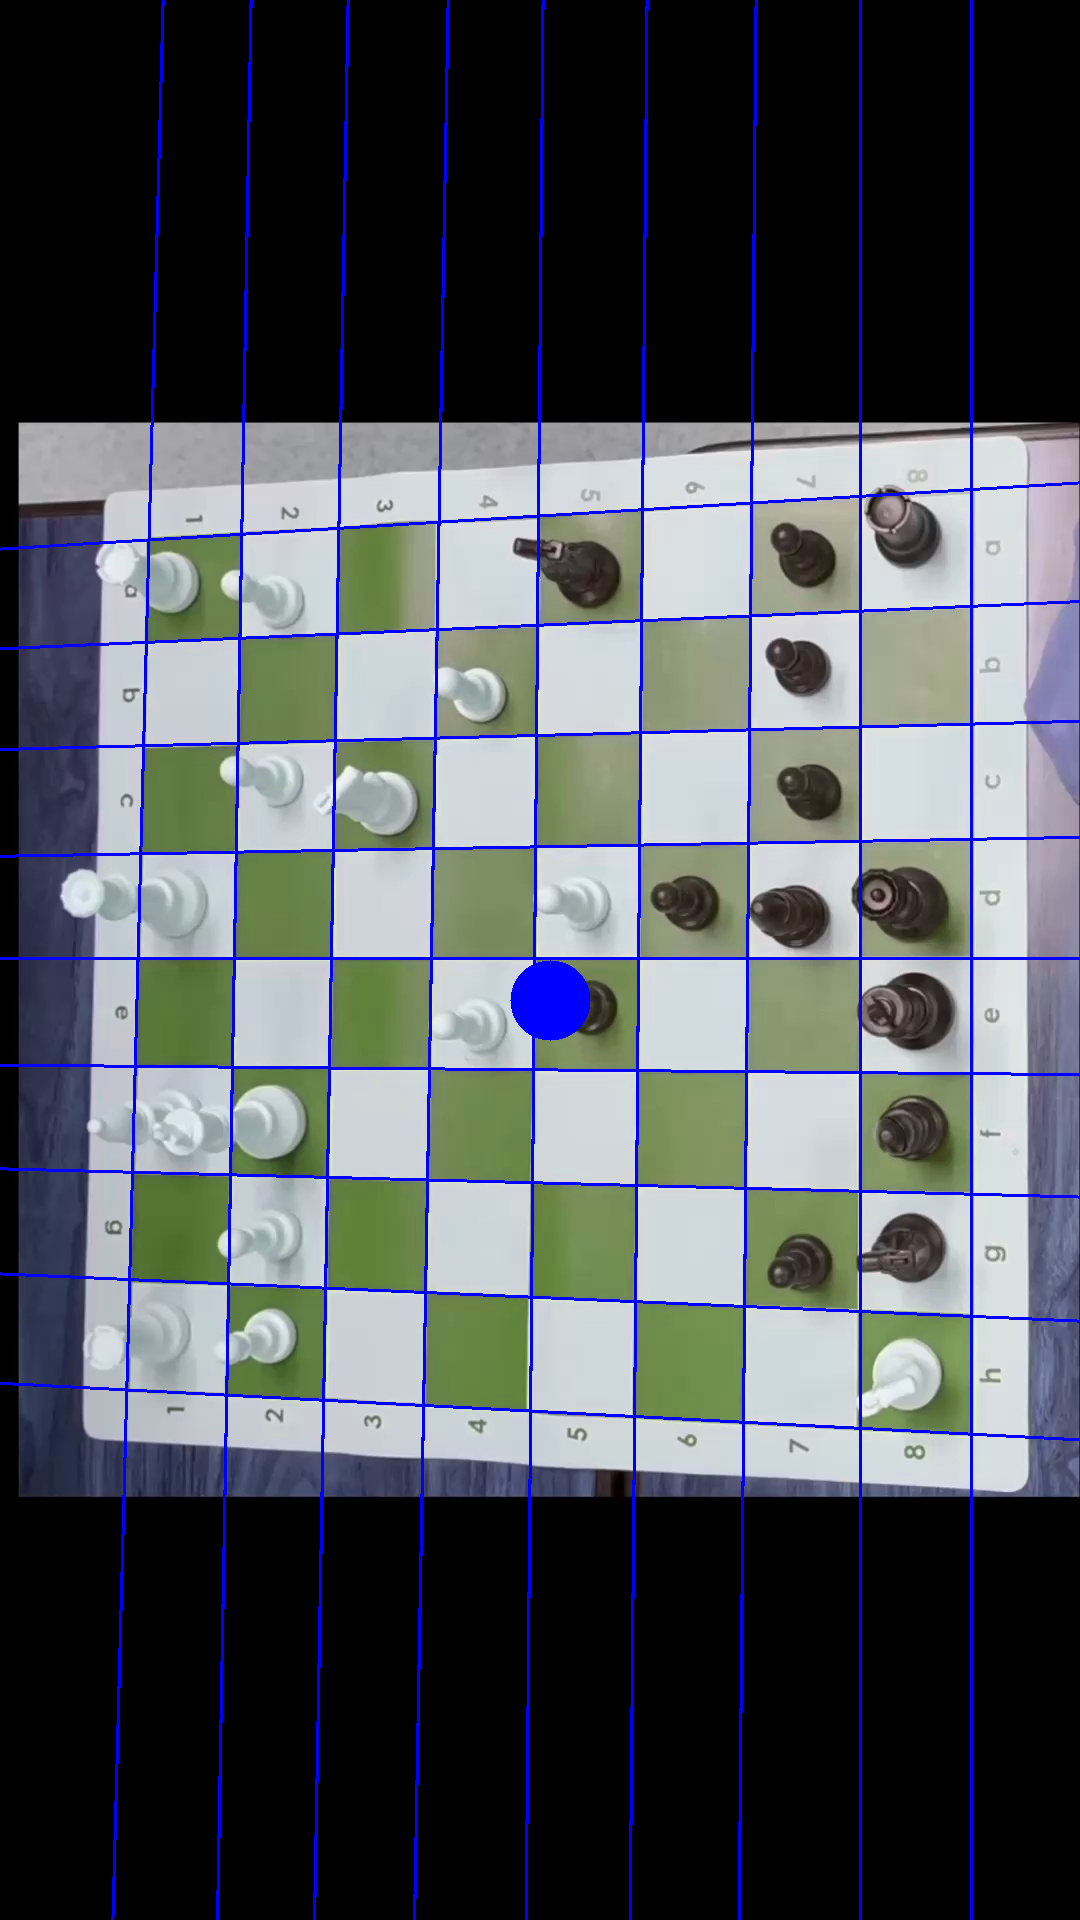

(4, 4)
(1920, 1080, 3)


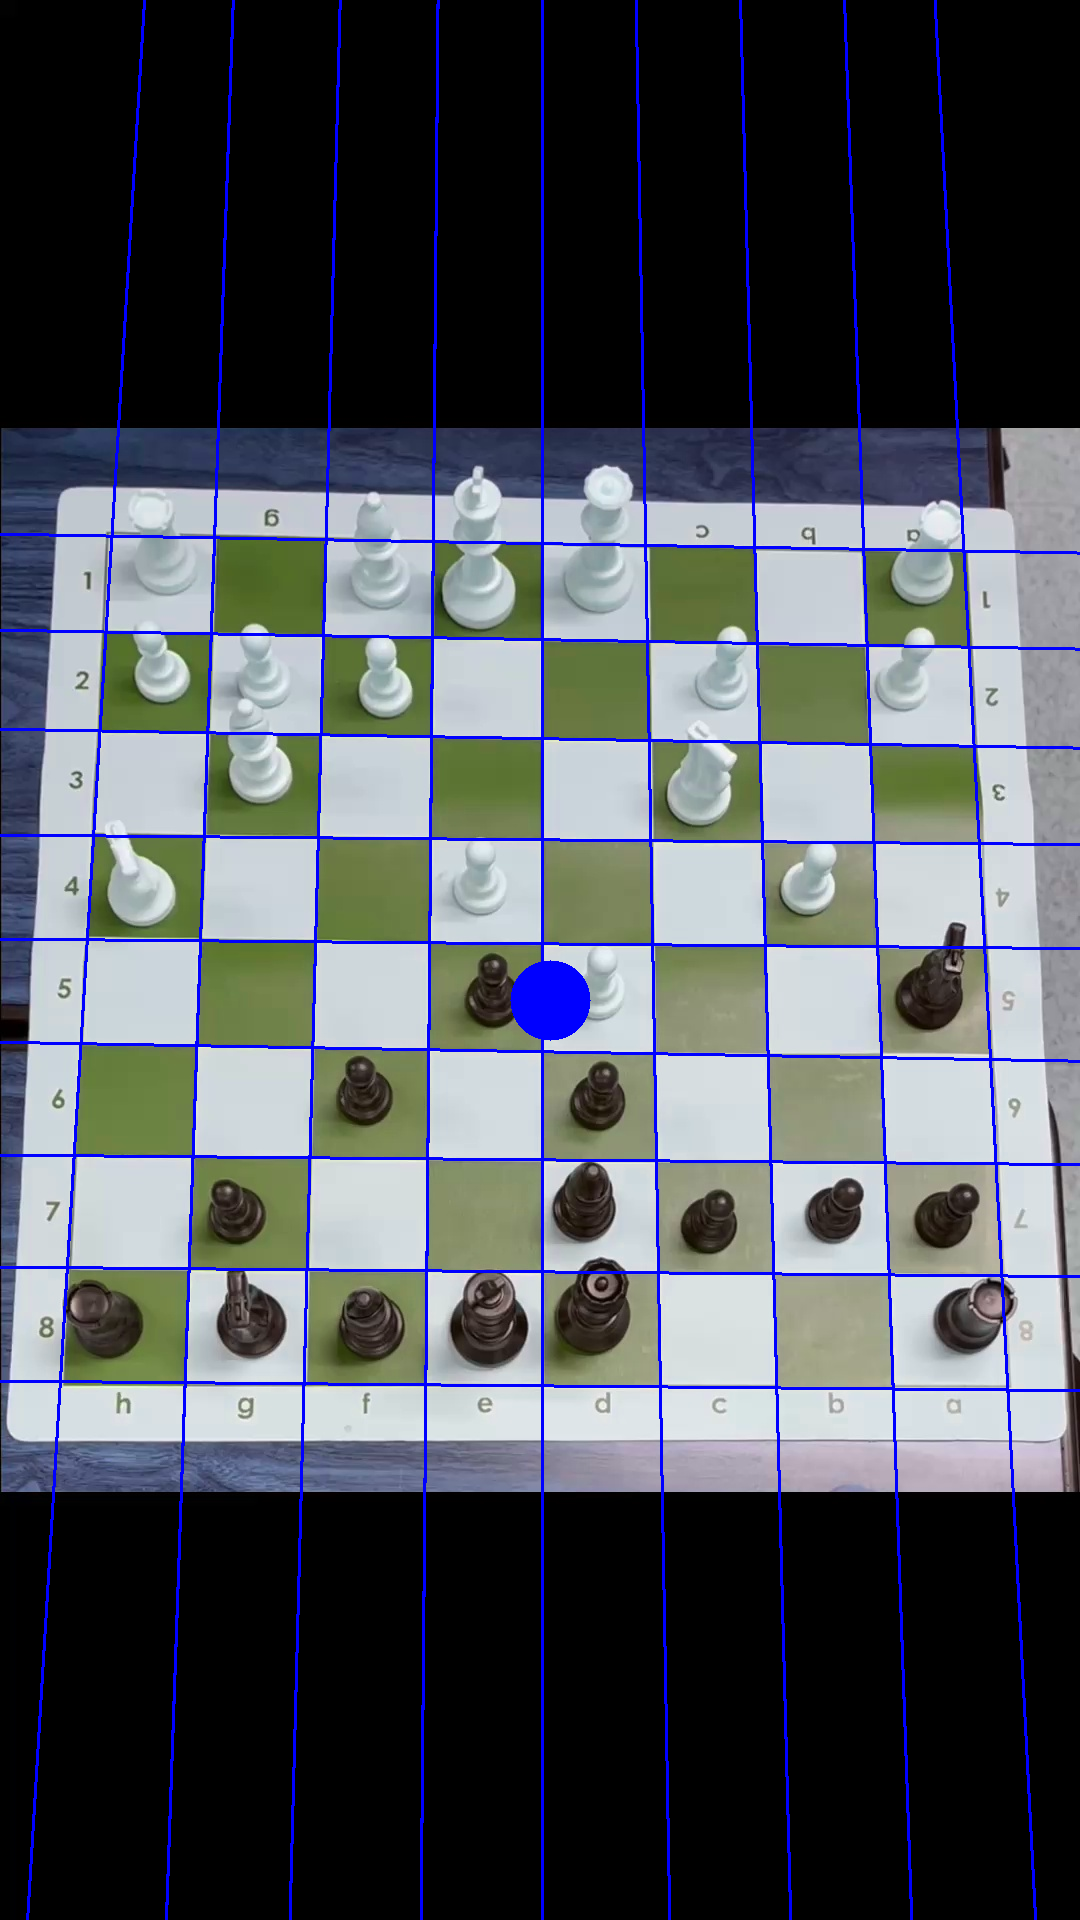

(4, 4)
(1920, 1080, 3)


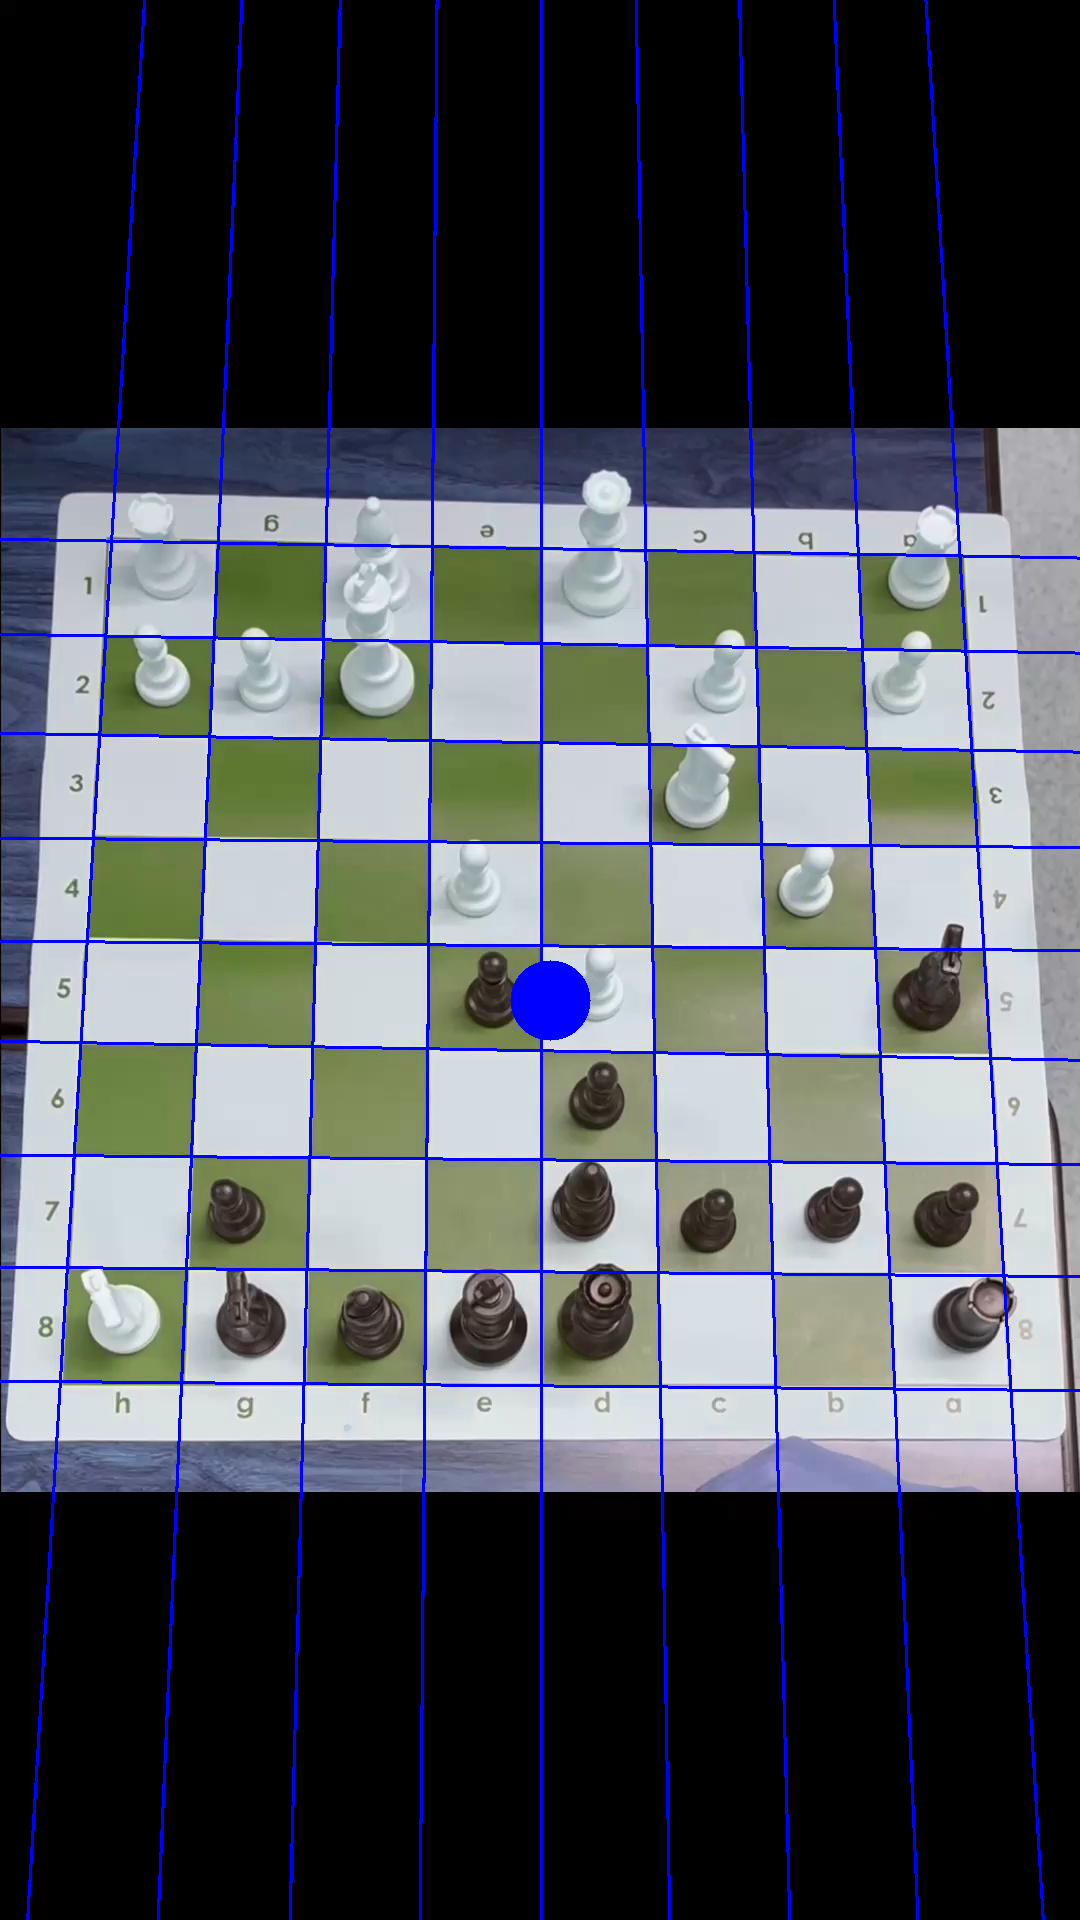

(4, 4)
(1920, 1080, 3)


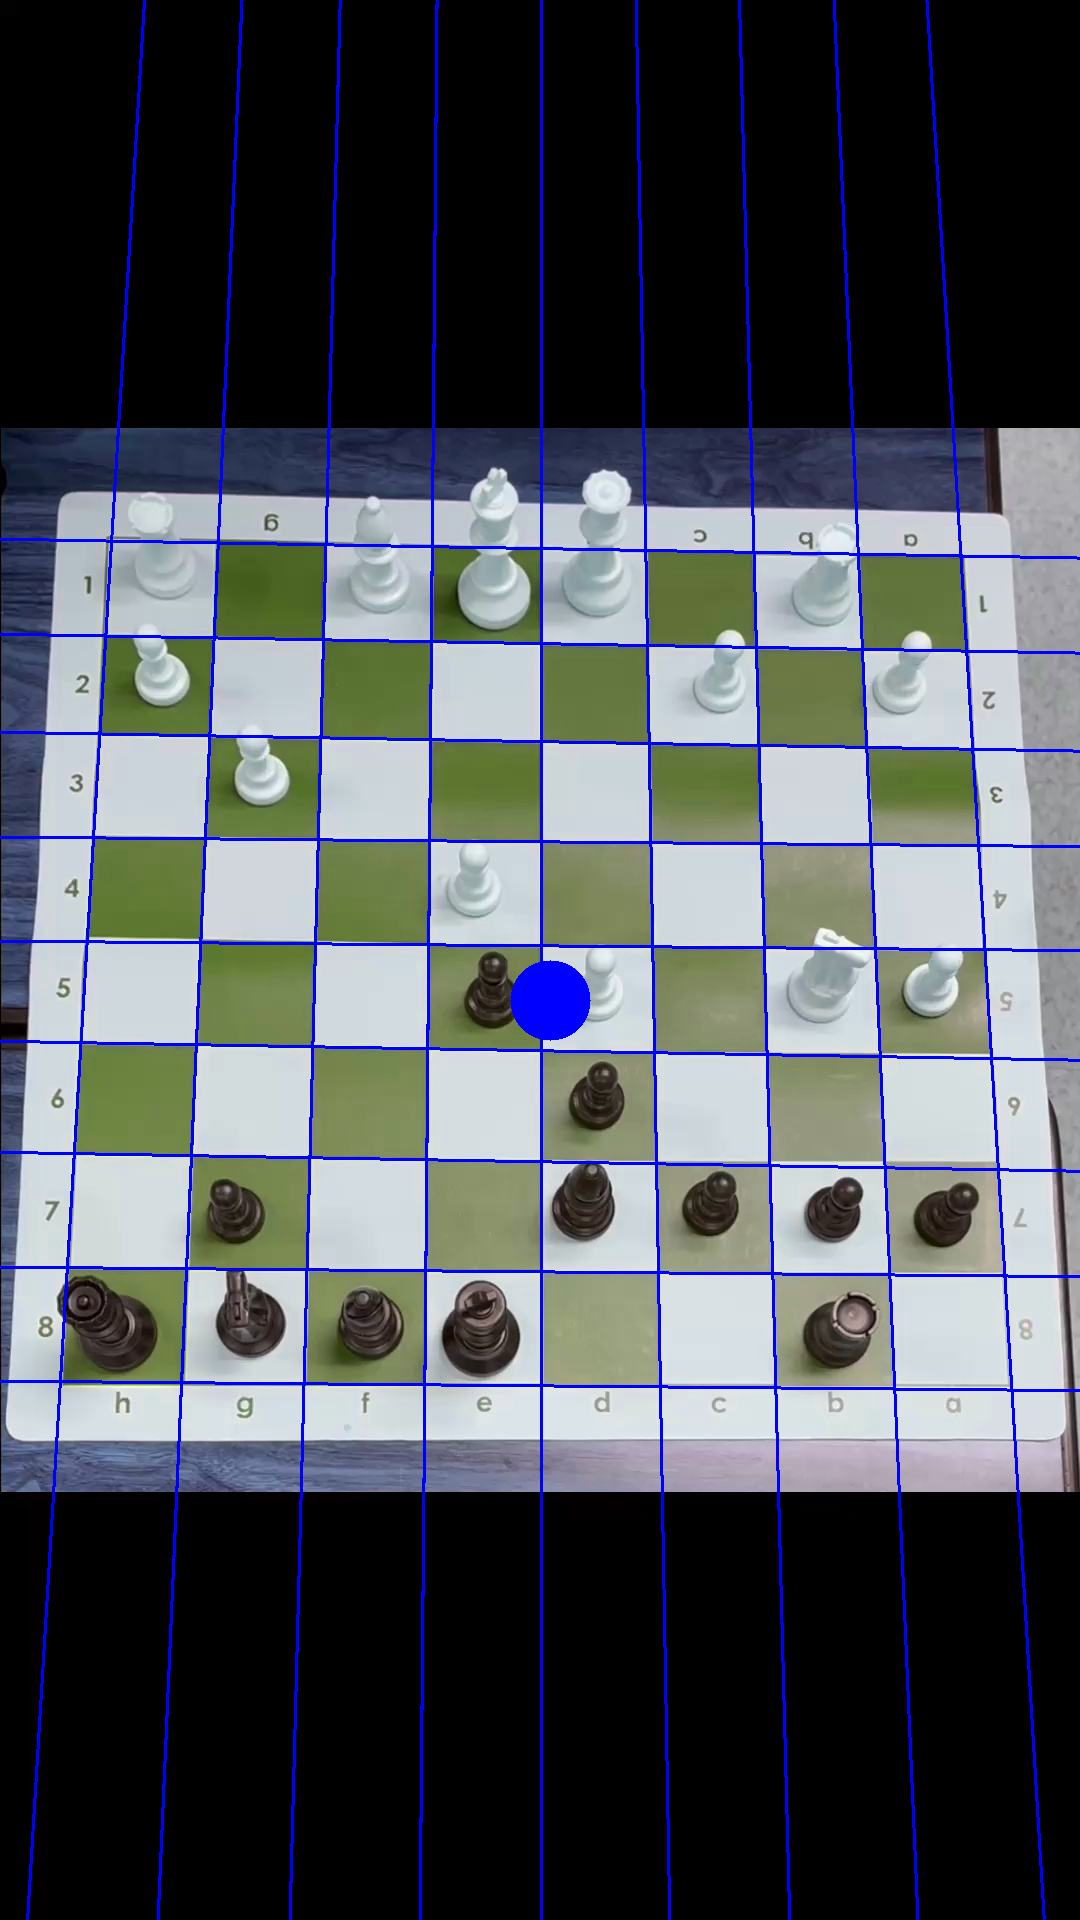

(4, 4)


In [21]:
# load image

def testGrid(path):
    
    image = cv2.imread(path)
    print(image.shape)
    VerticalResult, HorizontalResult = gridDetect(image, 88, 178, (image.shape[0]//2, image.shape[1]//2), 250)
    embededLine(image, VerticalResult + HorizontalResult)
    point = (1000, 550)
    embededPoint(image, point)
    display(Image.fromarray(image))
    print(cellDetect(HorizontalResult, VerticalResult, point))


testGrid("examplePic/2_Move_rotate_studentcap.jpg")
testGrid("examplePic/4_Move_studetcap.jpg")
testGrid("examplePic/captured_frame.jpg")
testGrid("examplePic/captured_frame6_move_student.jpg")
